# Autonomous Drone-Based Vision System for Crop Health Monitoring and Disease Classification

**Module:** Advanced Robotics Automation and Computer Vision  
**Task 1:** Deep-learning vision module for crop disease classification  
**Model:** MobileNetV2 transfer learning + controlled fine-tuning  
**Dataset:** PlantVillage (Kaggle mirror)

This revised notebook keeps the original project design but corrects the validation/evaluation pipeline and adds stronger evidence for the report: reproducibility, class-imbalance handling, fine-tuning, multi-metric evaluation, ROC/PR analysis, edge-case stress testing, architecture visualisation, prediction examples, and TensorFlow Lite export for edge deployment.

> **Important:** Run all cells in Google Colab and use **your own generated outputs/screenshots** in the report. Do not invent results. Explain the choices in your own words and follow your tutor's rules for declaring/citing AI assistance.

> Add blockquote



## 1. Environment Setup and Reproducibility
A fixed seed helps make the train/validation split and experiments repeatable. This is useful when comparing model versions and documenting the experiment.

In [ ]:
!pip install -q tensorflow kagglehub scikit-learn seaborn matplotlib pandas pydot

import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU devices: []


## 2. Dataset Acquisition — PlantVillage
The assignment permits PlantVillage. The helper below locates the actual class-directory level because Kaggle mirrors sometimes add an extra parent folder.

In [ ]:
import kagglehub

DOWNLOAD_ROOT = Path(kagglehub.dataset_download('emmarex/plantdisease'))
print('Dataset downloaded to:', DOWNLOAD_ROOT)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def looks_like_class_root(folder: Path, min_classes=2):
    if not folder.is_dir():
        return False
    subdirs = [d for d in folder.iterdir() if d.is_dir()]
    class_like = 0
    for d in subdirs:
        if any(f.suffix.lower() in IMAGE_EXTS for f in d.iterdir() if f.is_file()):
            class_like += 1
    return class_like >= min_classes

candidates = [DOWNLOAD_ROOT]
for d in DOWNLOAD_ROOT.iterdir():
    if d.is_dir():
        candidates.append(d)
        candidates.extend([x for x in d.iterdir() if x.is_dir()])

DATASET_DIR = next((p for p in candidates if looks_like_class_root(p)), None)
if DATASET_DIR is None:
    raise FileNotFoundError('Could not locate the PlantVillage class folders. Inspect DOWNLOAD_ROOT manually.')

print('Using class root:', DATASET_DIR)

Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded to: /kaggle/input/plantdisease
Using class root: /kaggle/input/plantdisease/PlantVillage


Number of classes: 15
Total images: 20638


,class,images
0,Tomato__Tomato_YellowLeaf__Curl_Virus,3208
1,Tomato_Bacterial_spot,2127
2,Tomato_Late_blight,1909
3,Tomato_Septoria_leaf_spot,1771
4,Tomato_Spider_mites_Two_spotted_spider_mite,1676
5,Tomato_healthy,1591
6,Pepper__bell___healthy,1478
7,Tomato__Target_Spot,1404
8,Potato___Early_blight,1000
9,Potato___Late_blight,1000


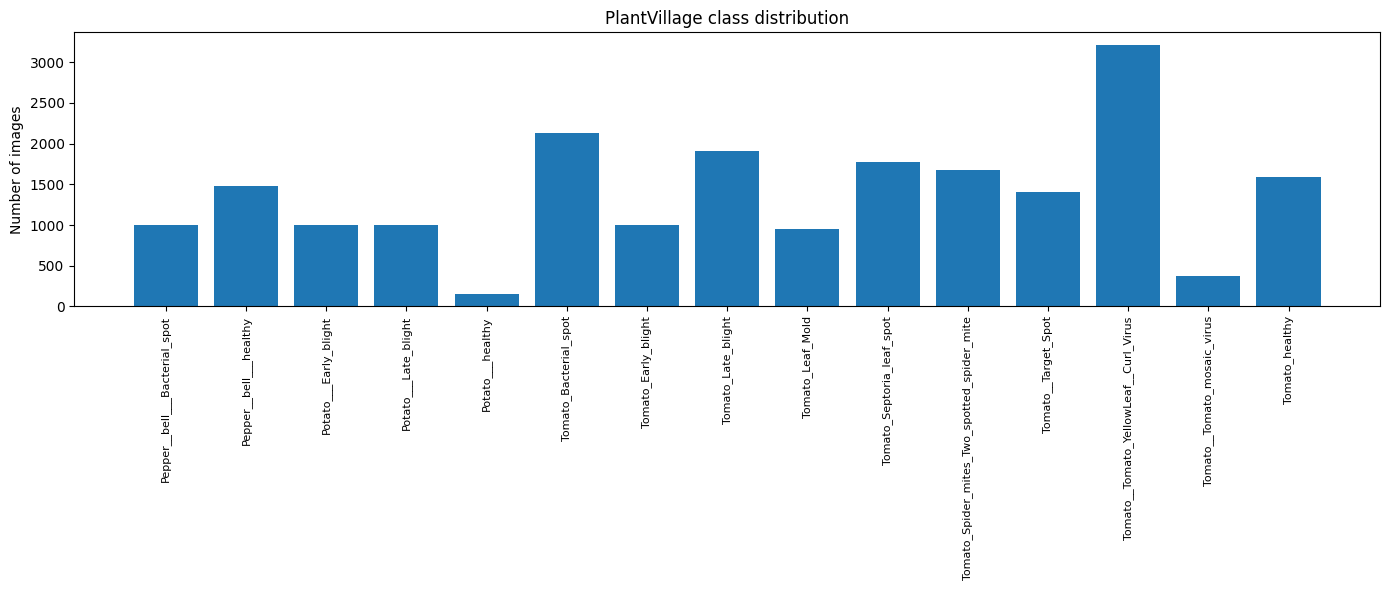

In [ ]:
# Class distribution and dataset size
class_counts = {}
for cls in sorted(os.listdir(DATASET_DIR)):
    cls_path = Path(DATASET_DIR) / cls
    if cls_path.is_dir():
        count = sum(1 for f in cls_path.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXTS)
        if count:
            class_counts[cls] = count

counts_df = pd.DataFrame({'class': list(class_counts.keys()), 'images': list(class_counts.values())})
print('Number of classes:', len(counts_df))
print('Total images:', int(counts_df['images'].sum()))
display(counts_df.sort_values('images', ascending=False).reset_index(drop=True))

plt.figure(figsize=(14, 6))
plt.bar(counts_df['class'], counts_df['images'])
plt.xticks(rotation=90, fontsize=8)
plt.ylabel('Number of images')
plt.title('PlantVillage class distribution')
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Data Preparation and Drone-Condition Augmentation

**Key correction from the earlier version:** augmentation is applied **only to the training data**. Validation data receives deterministic preprocessing only and uses `shuffle=False`. This keeps evaluation labels aligned with predictions and avoids measuring performance on randomly augmented validation images.

Training augmentation approximates several drone-view challenges: camera angle, scale/altitude variation, position shift, horizontal viewpoint changes, and changing illumination. PlantVillage is still a close-up laboratory-style dataset, so these augmentations reduce—but do not remove—the domain gap to real aerial imagery.

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
VAL_SPLIT = 0.20

train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    brightness_range=[0.6, 1.4],
    zoom_range=0.20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    horizontal_flip=True,
    validation_split=VAL_SPLIT
)

val_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=VAL_SPLIT
)

train_data = train_gen.flow_from_directory(
    str(DATASET_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

val_data = val_gen.flow_from_directory(
    str(DATASET_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)

NUM_CLASSES = train_data.num_classes
class_labels = list(train_data.class_indices.keys())
assert train_data.class_indices == val_data.class_indices

print('Training images:', train_data.samples)
print('Validation images:', val_data.samples)
print('Classes:', NUM_CLASSES)

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
Training images: 16516
Validation images: 4122
Classes: 15


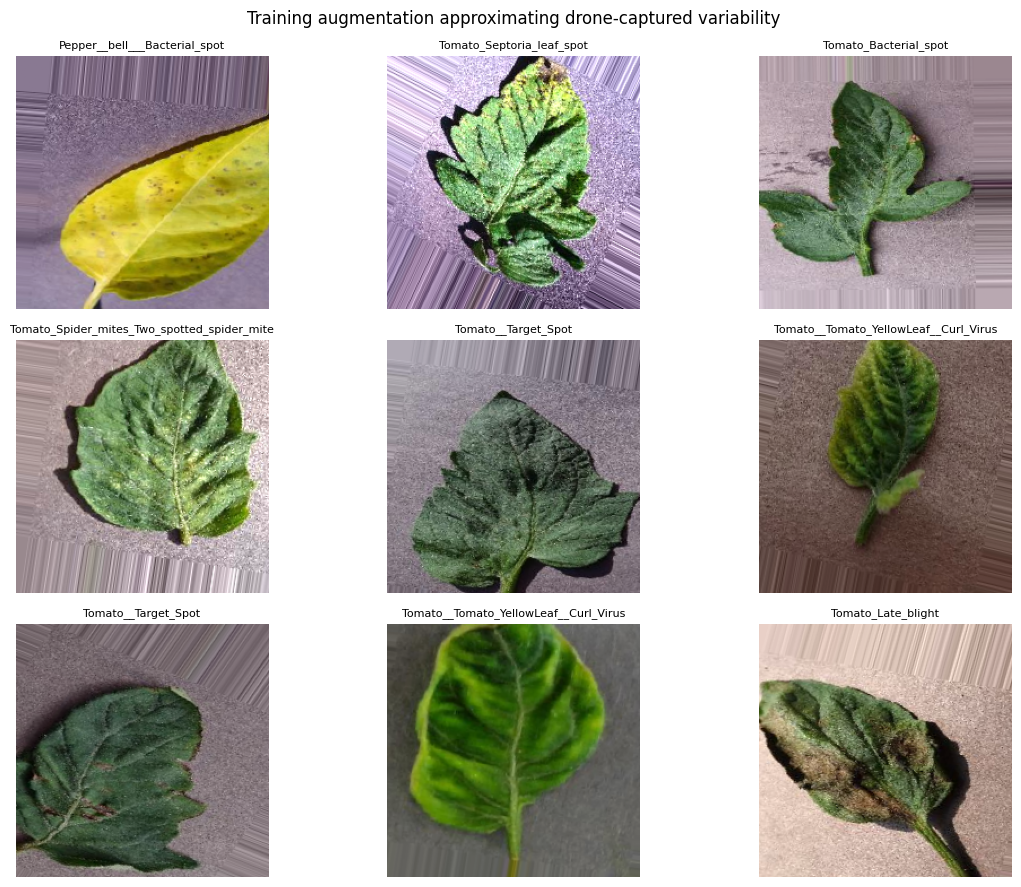

In [ ]:
# Visualise augmented training images
images, labels = next(train_data)
show_images = np.clip((images + 1.0) / 2.0, 0, 1)  # undo MobileNetV2 preprocessing for display only

plt.figure(figsize=(12, 9))
for i in range(min(9, len(show_images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(show_images[i])
    plt.title(class_labels[np.argmax(labels[i])], fontsize=8)
    plt.axis('off')
plt.suptitle('Training augmentation approximating drone-captured variability')
plt.tight_layout()
plt.savefig('augmented_samples.png', dpi=200, bbox_inches='tight')
plt.show()

### Class imbalance handling
Class weights are calculated from the training split. This prevents larger classes from dominating the loss and gives minority classes more influence during optimisation.

In [ ]:
classes_present = np.unique(train_data.classes)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes_present,
    y=train_data.classes
)
class_weights = {int(c): float(w) for c, w in zip(classes_present, weights)}

weight_df = pd.DataFrame({
    'class': [class_labels[i] for i in classes_present],
    'weight': [class_weights[int(i)] for i in classes_present]
}).sort_values('weight', ascending=False)
display(weight_df.reset_index(drop=True))

,class,weight
0,Potato___healthy,9.025137
1,Tomato__Tomato_mosaic_virus,3.682497
2,Tomato_Leaf_Mold,1.444969
3,Pepper__bell___Bacterial_spot,1.379783
4,Potato___Late_blight,1.376333
5,Tomato_Early_blight,1.376333
6,Potato___Early_blight,1.376333
7,Tomato__Target_Spot,0.979597
8,Pepper__bell___healthy,0.930741
9,Tomato_healthy,0.864938


## 4. Model Architecture — MobileNetV2 Transfer Learning
MobileNetV2 is appropriate for an edge-oriented drone vision prototype because it uses depthwise-separable convolutions and inverted residual blocks, reducing parameter count and computation relative to heavier CNN backbones. ImageNet pretraining also gives useful low-level visual features before adapting to plant-disease classes.

In [ ]:
base_model = MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(NUM_CLASSES, activation='softmax')
], name='PlantDisease_MobileNetV2')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()
print('Total parameters:', f'{model.count_params():,}')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "PlantDisease_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,887 (9.25 MB)

 Trainable params: 165,903 (648.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameters: 2,423,887


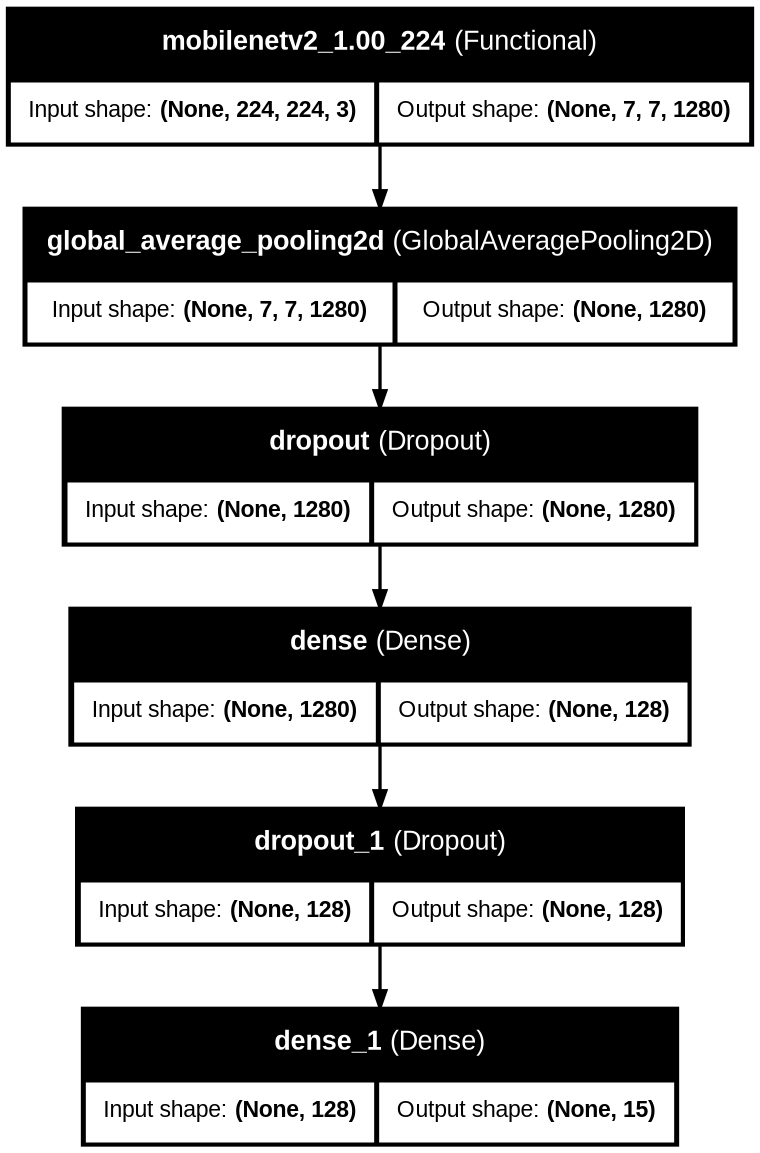

In [ ]:
# Architecture figure for the report
try:
    tf.keras.utils.plot_model(
        model,
        to_file='mobilenetv2_architecture.png',
        show_shapes=True,
        show_layer_names=True,
        expand_nested=False,
        dpi=120
    )
    from IPython.display import Image, display
    display(Image('mobilenetv2_architecture.png'))
except Exception as e:
    print('Architecture image could not be rendered:', e)
    print('Use the model.summary() output as the layer breakdown.')

## 5. Training Strategy
The experiment uses two stages:
1. **Feature extraction:** freeze the ImageNet backbone and train only the classifier head.
2. **Fine-tuning:** unfreeze the final MobileNetV2 layers with a much smaller learning rate, while keeping Batch Normalisation layers frozen for stability.

Early stopping and learning-rate reduction limit unnecessary training and reduce overfitting risk.

In [ ]:
callbacks_stage1 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'best_stage1.keras', monitor='val_accuracy', save_best_only=True, verbose=1
    )
]

INITIAL_EPOCHS = 8
history1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks_stage1,
    class_weight=class_weights
)

Epoch 1/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5421 - loss: 1.4263
Epoch 1: val_accuracy improved from None to 0.83624, saving model to best_stage1.keras

Epoch 1: finished saving model to best_stage1.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 1194s 2s/step - accuracy: 0.6609 - loss: 1.0253 - val_accuracy: 0.8362 - val_loss: 0.5184 - learning_rate: 0.0010
Epoch 2/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7706 - loss: 0.6547
Epoch 2: val_accuracy improved from 0.83624 to 0.85711, saving model to best_stage1.keras

Epoch 2: finished saving model to best_stage1.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 1066s 2s/step - accuracy: 0.7774 - loss: 0.6420 - val_accuracy: 0.8571 - val_loss: 0.4398 - learning_rate: 0.0010
Epoch 3/8
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7994 - loss: 0.5708
Epoch 3: val_accuracy improved from 0.85711 to 0.86536, saving model to best_stage1.keras

Epoch 3: finished saving model to best_stage1.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 1053s 2

In [ ]:
# Controlled fine-tuning of the final MobileNetV2 layers
base_model.trainable = True
FINE_TUNE_LAYERS = 30

for layer in base_model.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers[-FINE_TUNE_LAYERS:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks_stage2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'best_finetuned.keras', monitor='val_accuracy', save_best_only=True, verbose=1
    )
]

completed_stage1 = len(history1.history['loss'])
FINE_TUNE_EPOCHS = 5
history2 = model.fit(
    train_data,
    validation_data=val_data,
    initial_epoch=completed_stage1,
    epochs=completed_stage1 + FINE_TUNE_EPOCHS,
    callbacks=callbacks_stage2,
    class_weight=class_weights
)

Epoch 9/13
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8626 - loss: 0.3965
Epoch 9: val_accuracy improved from None to 0.89059, saving model to best_finetuned.keras

Epoch 9: finished saving model to best_finetuned.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 1260s 2s/step - accuracy: 0.8663 - loss: 0.3817 - val_accuracy: 0.8906 - val_loss: 0.3228 - learning_rate: 1.0000e-05
Epoch 10/13
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8812 - loss: 0.3459
Epoch 10: val_accuracy improved from 0.89059 to 0.89884, saving model to best_finetuned.keras

Epoch 10: finished saving model to best_finetuned.keras
517/517 ━━━━━━━━━━━━━━━━━━━━ 1257s 2s/step - accuracy: 0.8836 - loss: 0.3373 - val_accuracy: 0.8988 - val_loss: 0.2913 - learning_rate: 1.0000e-05
Epoch 11/13
517/517 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8915 - loss: 0.3120
Epoch 11: val_accuracy improved from 0.89884 to 0.91533, saving model to best_finetuned.keras

Epoch 11: finished saving model to best_finetuned.keras
5

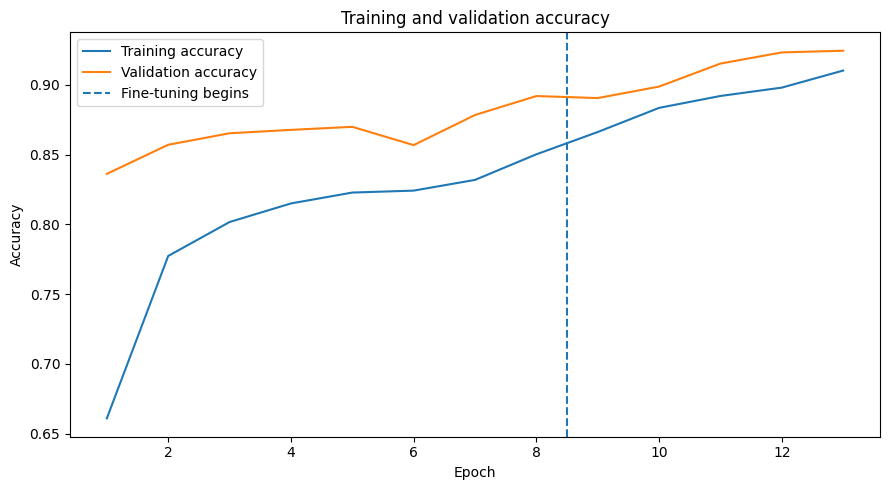

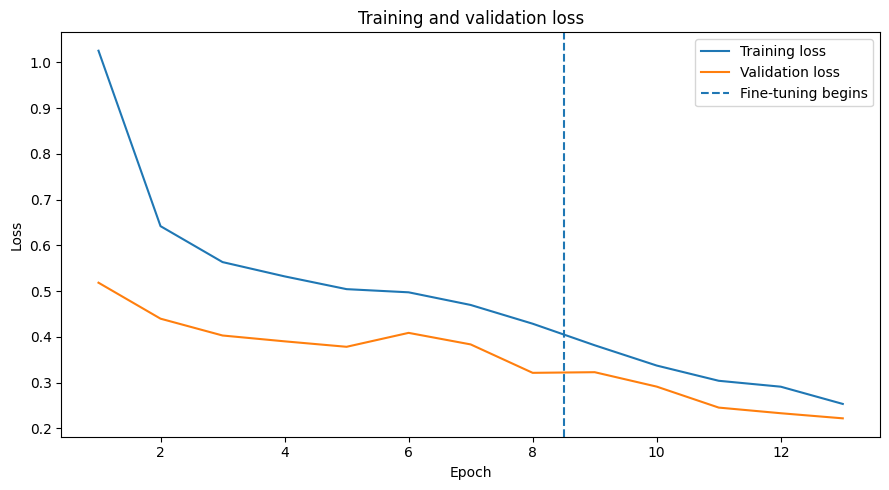

In [ ]:
# Combined training curves
train_acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
train_loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

epochs = range(1, len(train_acc) + 1)
fine_tune_start = len(history1.history['accuracy'])

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_acc, label='Training accuracy')
plt.plot(epochs, val_acc, label='Validation accuracy')
plt.axvline(fine_tune_start + 0.5, linestyle='--', label='Fine-tuning begins')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and validation accuracy')
plt.legend()
plt.tight_layout()
plt.savefig('accuracy_curve.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.axvline(fine_tune_start + 0.5, linestyle='--', label='Fine-tuning begins')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and validation loss')
plt.legend()
plt.tight_layout()
plt.savefig('loss_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Model Evaluation
Because `val_data` is not shuffled, the validation labels and prediction order remain aligned. The report should include accuracy plus macro/weighted precision, recall and F1 rather than accuracy alone, especially because class frequencies are not identical.

In [ ]:
val_data.reset()
y_true = val_data.classes
y_prob = model.predict(val_data, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average='macro', zero_division=0
)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average='weighted', zero_division=0
)

summary_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1',
               'Weighted Precision', 'Weighted Recall', 'Weighted F1'],
    'Score': [accuracy, macro_p, macro_r, macro_f1,
              weighted_p, weighted_r, weighted_f1]
})
display(summary_metrics.style.format({'Score': '{:.4f}'}))

report_dict = classification_report(
    y_true, y_pred,
    target_names=class_labels,
    output_dict=True,
    zero_division=0
)
per_class_df = pd.DataFrame(report_dict).T.iloc[:NUM_CLASSES]
per_class_df = per_class_df.sort_values('f1-score')
print('Classes needing the most improvement (lowest F1):')
display(per_class_df.head(10).style.format('{:.3f}'))

# Save exact metrics for report writing later
summary_metrics.to_csv('summary_metrics.csv', index=False)
per_class_df.to_csv('per_class_metrics.csv')

129/129 ━━━━━━━━━━━━━━━━━━━━ 170s 1s/step


,Metric,Score
0,Accuracy,0.9246
1,Macro Precision,0.9152
2,Macro Recall,0.9272
3,Macro F1,0.9194
4,Weighted Precision,0.9274
5,Weighted Recall,0.9246
6,Weighted F1,0.9245


Classes needing the most improvement (lowest F1):


,precision,recall,f1-score,support
Tomato_Early_blight,0.860,0.765,0.810,200.000
Tomato__Target_Spot,0.886,0.775,0.827,280.000
Tomato_Leaf_Mold,0.770,0.984,0.864,190.000
Tomato_Septoria_leaf_spot,0.863,0.910,0.886,354.000
Tomato_Spider_mites_Two_spotted_spider_mite,0.872,0.913,0.892,335.000
Tomato__Tomato_mosaic_virus,0.875,0.946,0.909,74.000
Tomato_Late_blight,0.935,0.913,0.924,381.000
Tomato_Bacterial_spot,0.970,0.901,0.934,425.000
Potato___healthy,0.906,0.967,0.935,30.000
Pepper__bell___Bacterial_spot,0.941,0.970,0.955,199.000


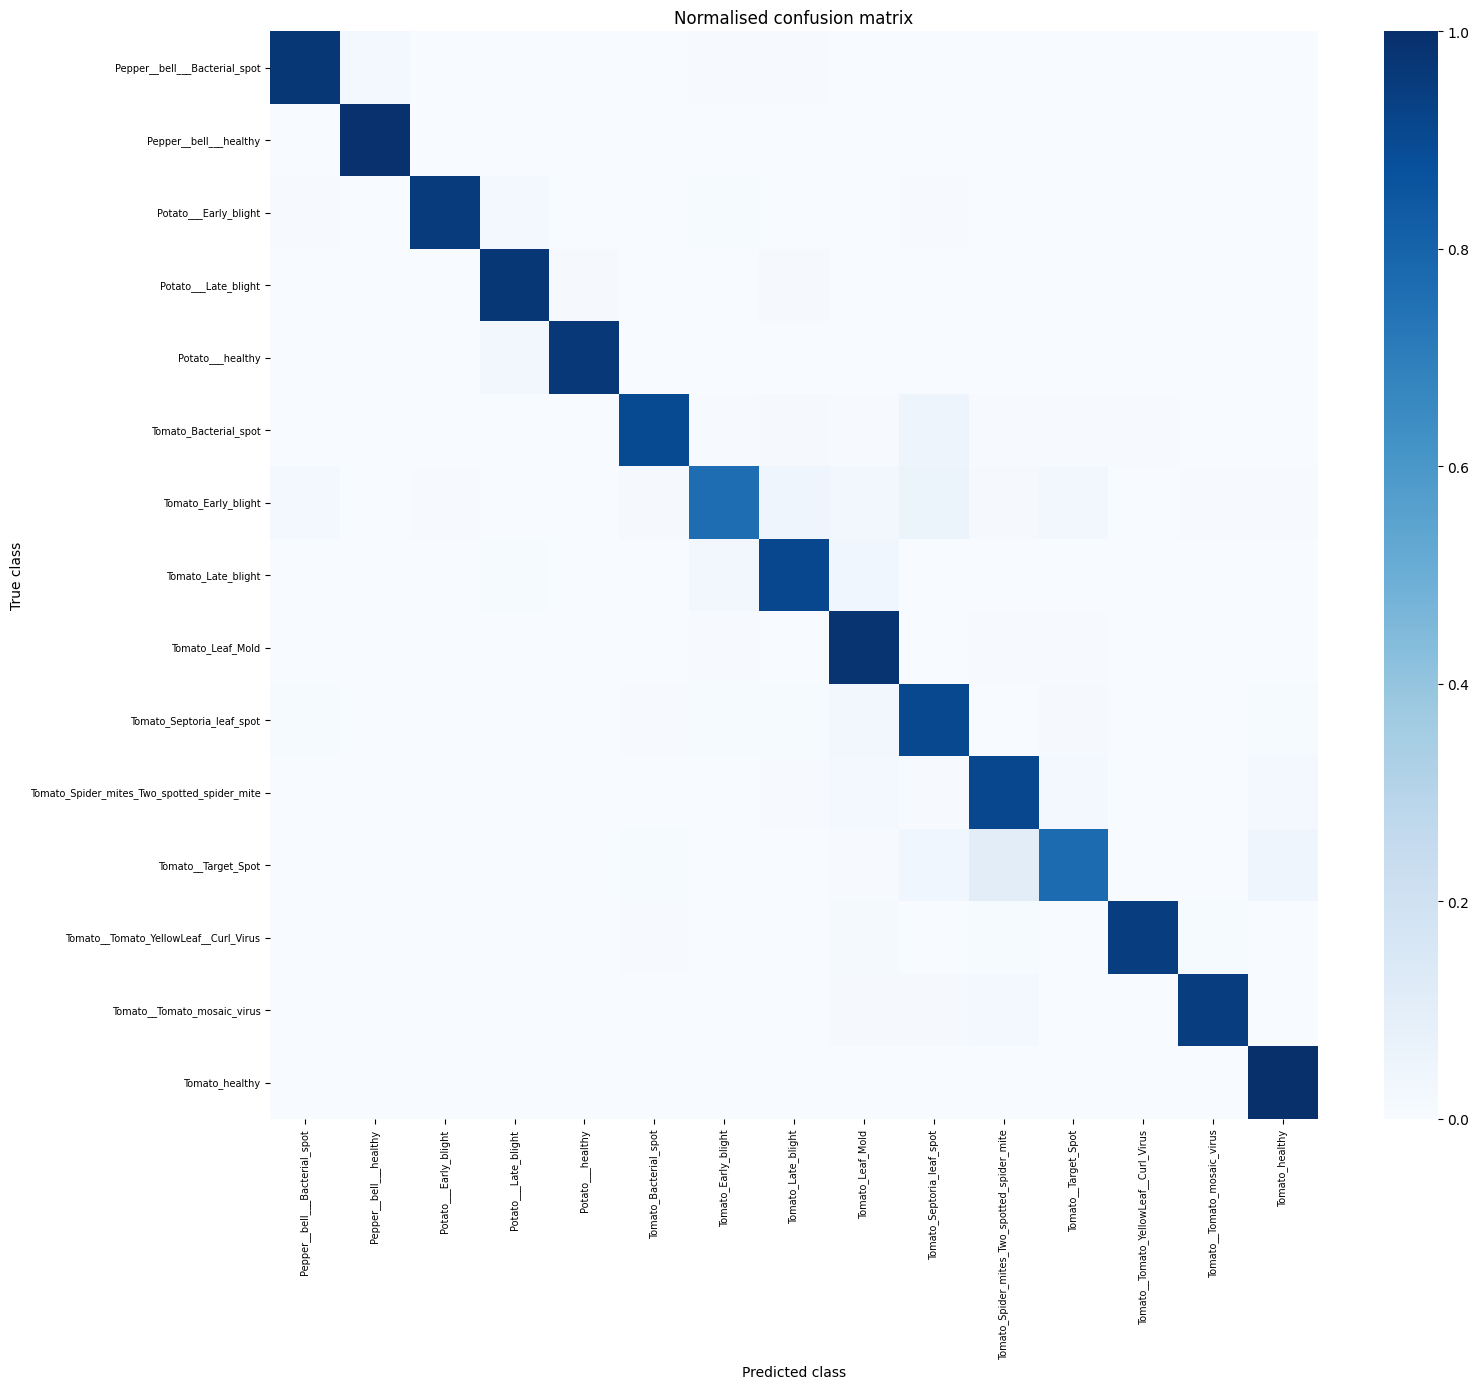

Largest confusion pairs:


,count,true_class,predicted_as
0,30,Tomato__Target_Spot,Tomato_Spider_mites_Two_spotted_spider_mite
1,22,Tomato_Bacterial_spot,Tomato_Septoria_leaf_spot
2,14,Tomato__Target_Spot,Tomato_healthy
3,14,Tomato_Late_blight,Tomato_Leaf_Mold
4,13,Tomato_Late_blight,Tomato_Early_blight
5,12,Tomato_Septoria_leaf_spot,Tomato_Leaf_Mold
6,12,Tomato_Early_blight,Tomato_Septoria_leaf_spot
7,11,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato_Leaf_Mold
8,10,Tomato__Target_Spot,Tomato_Septoria_leaf_spot
9,9,Tomato_Early_blight,Tomato_Late_blight


In [ ]:
# Normalised confusion matrix for readability across unequal class sizes
cm = confusion_matrix(y_true, y_pred)
cm_norm = confusion_matrix(y_true, y_pred, normalize='true')

plt.figure(figsize=(16, 14))
sns.heatmap(
    cm_norm,
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1
)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Normalised confusion matrix')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig('confusion_matrix_normalised.png', dpi=220, bbox_inches='tight')
plt.show()

# Identify the largest off-diagonal confusions for critical analysis
pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            pairs.append((int(cm[i, j]), class_labels[i], class_labels[j]))

confusions_df = pd.DataFrame(
    sorted(pairs, reverse=True)[:15],
    columns=['count', 'true_class', 'predicted_as']
)
print('Largest confusion pairs:')
display(confusions_df)
confusions_df.to_csv('largest_confusions.csv', index=False)

### Multi-class ROC and Precision–Recall analysis
For many classes, plotting every one-vs-rest curve would be unreadable. The notebook therefore reports **macro one-vs-rest ROC-AUC** numerically and plots **micro-average ROC and PR curves** as compact global summaries.

Macro ROC-AUC (OvR): 0.9973
Micro ROC-AUC: 0.9980
Micro Average Precision: 0.9789


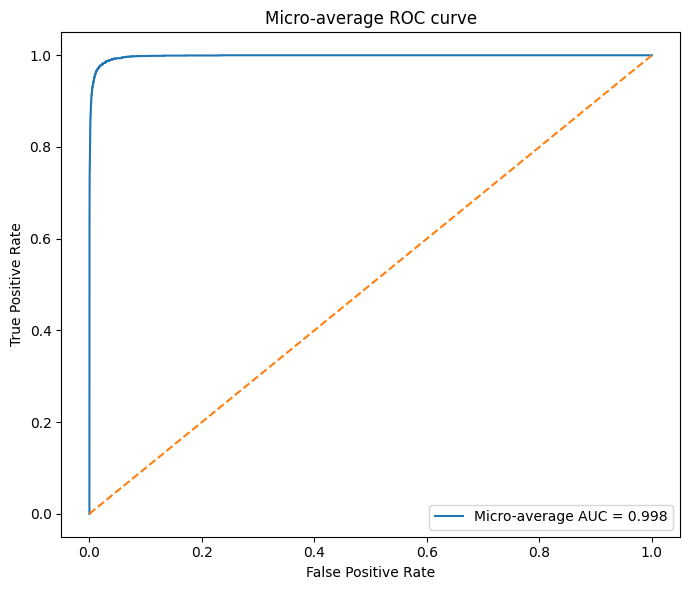

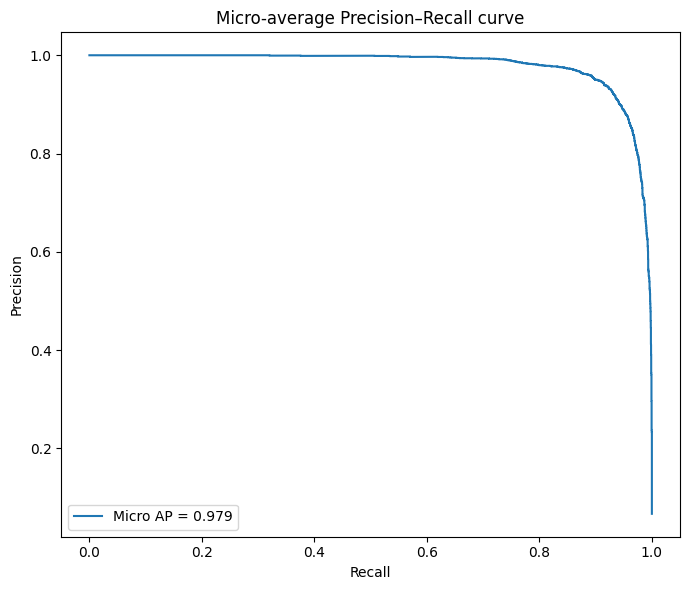

In [ ]:
y_true_1h = tf.keras.utils.to_categorical(y_true, num_classes=NUM_CLASSES)

macro_roc_auc = roc_auc_score(y_true_1h, y_prob, average='macro', multi_class='ovr')
micro_fpr, micro_tpr, _ = roc_curve(y_true_1h.ravel(), y_prob.ravel())
micro_roc_auc = auc(micro_fpr, micro_tpr)

micro_precision, micro_recall, _ = precision_recall_curve(y_true_1h.ravel(), y_prob.ravel())
micro_ap = average_precision_score(y_true_1h, y_prob, average='micro')

print(f'Macro ROC-AUC (OvR): {macro_roc_auc:.4f}')
print(f'Micro ROC-AUC: {micro_roc_auc:.4f}')
print(f'Micro Average Precision: {micro_ap:.4f}')

plt.figure(figsize=(7, 6))
plt.plot(micro_fpr, micro_tpr, label=f'Micro-average AUC = {micro_roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Micro-average ROC curve')
plt.legend()
plt.tight_layout()
plt.savefig('roc_micro.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(7, 6))
plt.plot(micro_recall, micro_precision, label=f'Micro AP = {micro_ap:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Micro-average Precision–Recall curve')
plt.legend()
plt.tight_layout()
plt.savefig('pr_micro.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Edge-Case Robustness Stress Test
The brief asks for limitations and edge-case behaviour. This controlled test compares clean validation images with three synthetic degradations that can occur in drone imagery:
- lower illumination,
- horizontal motion blur,
- reduced spatial resolution followed by upscaling.

This is a **stress test**, not a substitute for evaluation on a genuine aerial field dataset.

,Condition,Accuracy,Images tested
0,Clean,0.9781,320
1,Low light,0.9563,320
2,Motion blur,0.8656,320
3,Low resolution,0.9719,320


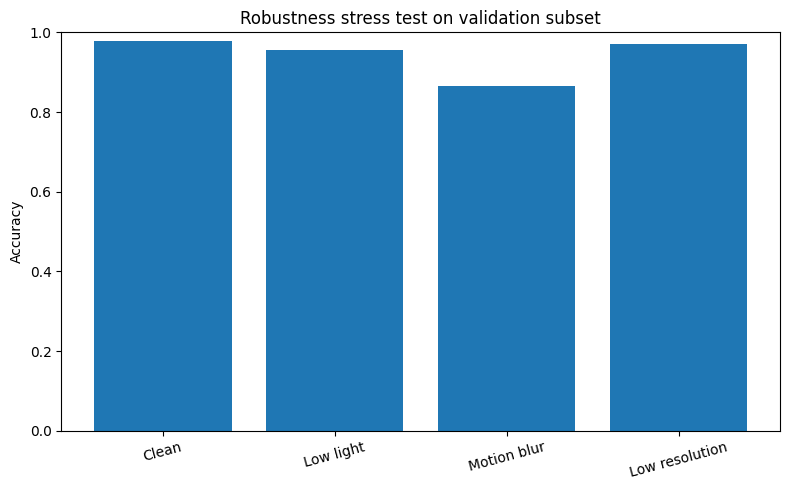

In [ ]:
def to_01(x):
    return tf.clip_by_value((tf.cast(x, tf.float32) + 1.0) / 2.0, 0.0, 1.0)

def to_mobilenet_range(x):
    return tf.clip_by_value(x * 2.0 - 1.0, -1.0, 1.0)

def make_dark(x):
    return to_mobilenet_range(to_01(x) * 0.55)

def make_motion_blur(x, kernel_width=7):
    z = to_01(x)
    channels = int(z.shape[-1])
    kernel = tf.ones((1, kernel_width, channels, 1), dtype=tf.float32) / float(kernel_width)
    blurred = tf.nn.depthwise_conv2d(z, kernel, strides=[1, 1, 1, 1], padding='SAME')
    return to_mobilenet_range(blurred)

def make_low_res(x):
    z = to_01(x)
    small = tf.image.resize(z, (112, 112), method='area')
    up = tf.image.resize(small, IMG_SIZE, method='bilinear')
    return to_mobilenet_range(up)

conditions = {
    'Clean': lambda x: x,
    'Low light': make_dark,
    'Motion blur': make_motion_blur,
    'Low resolution': make_low_res,
}

# Use up to 10 deterministic validation batches (state this sample size in the report)
N_BATCHES = min(10, len(val_data))
results = []

for condition_name, transform in conditions.items():
    total_correct = 0
    total_seen = 0
    for b in range(N_BATCHES):
        x_batch, y_batch = val_data[b]
        x_test = transform(x_batch)
        probs = model.predict(x_test, verbose=0)
        pred = np.argmax(probs, axis=1)
        true = np.argmax(y_batch, axis=1)
        total_correct += np.sum(pred == true)
        total_seen += len(true)
    results.append((condition_name, total_correct / total_seen, total_seen))

robustness_df = pd.DataFrame(results, columns=['Condition', 'Accuracy', 'Images tested'])
display(robustness_df.style.format({'Accuracy': '{:.4f}'}))
robustness_df.to_csv('robustness_stress_test.csv', index=False)

plt.figure(figsize=(8, 5))
plt.bar(robustness_df['Condition'], robustness_df['Accuracy'])
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.title('Robustness stress test on validation subset')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('robustness_stress_test.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Prediction Visualisation and Confidence
These examples provide qualitative evidence alongside the numerical metrics. Incorrect predictions are useful to discuss because they reveal failure modes rather than only showing successful cases.

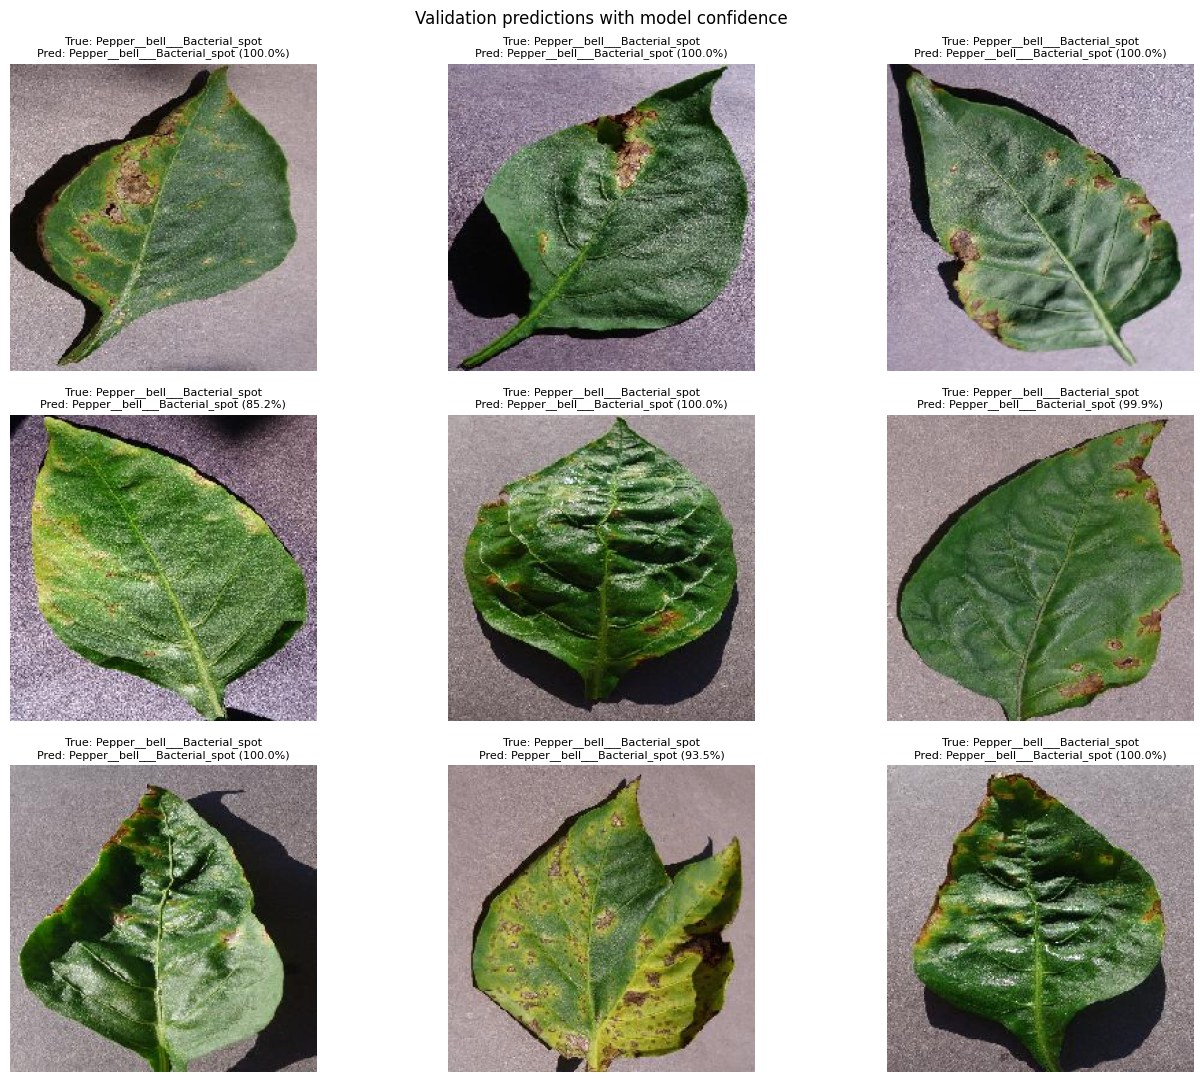

In [ ]:
val_data.reset()
images, labels = next(val_data)
probs = model.predict(images, verbose=0)

show_images = np.clip((images + 1.0) / 2.0, 0, 1)
plt.figure(figsize=(14, 11))
for i in range(min(9, len(show_images))):
    true_idx = int(np.argmax(labels[i]))
    pred_idx = int(np.argmax(probs[i]))
    confidence = float(np.max(probs[i])) * 100

    plt.subplot(3, 3, i + 1)
    plt.imshow(show_images[i])
    plt.title(
        f'True: {class_labels[true_idx]}\nPred: {class_labels[pred_idx]} ({confidence:.1f}%)',
        fontsize=8
    )
    plt.axis('off')

plt.suptitle('Validation predictions with model confidence')
plt.tight_layout()
plt.savefig('prediction_samples.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. Edge-Deployment Evidence — Keras and TensorFlow Lite
Saving both formats allows a simple model-size comparison. Float16 post-training quantisation is used for the TFLite version. The resulting file size is useful evidence for discussing embedded deployment, but **file size alone does not prove real-time performance on a Raspberry Pi/Jetson**; hardware-specific latency and power tests would still be required.

In [ ]:
KERAS_PATH = 'crop_disease_mobilenetv2_finetuned.keras'
model.save(KERAS_PATH)

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_model = converter.convert()

TFLITE_PATH = 'crop_disease_mobilenetv2_fp16.tflite'
with open(TFLITE_PATH, 'wb') as f:
    f.write(tflite_model)

keras_mb = os.path.getsize(KERAS_PATH) / (1024 ** 2)
tflite_mb = os.path.getsize(TFLITE_PATH) / (1024 ** 2)
reduction = 100 * (1 - tflite_mb / keras_mb)

size_df = pd.DataFrame({
    'Format': ['Keras', 'TFLite FP16'],
    'Size_MB': [keras_mb, tflite_mb]
})
display(size_df.style.format({'Size_MB': '{:.2f}'}))
print(f'Approximate file-size reduction: {reduction:.1f}%')

Saved artifact at '/tmp/tmplqgow1on'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 15), dtype=tf.float32, name=None)
Captures:
  139497766286160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764772112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764766160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764765968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764781136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764992016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764994128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764983184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764992208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764992400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139497764

,Format,Size_MB
0,Keras,22.61
1,TFLite FP16,4.58


Approximate file-size reduction: 79.8%


## 10. Critical Reflection — Evidence to Discuss in the Report
Use your **actual outputs** above to support a critical discussion rather than simply stating that the model performs well.

- **Domain gap:** PlantVillage contains mostly controlled close-up leaf images, while true drone imagery contains clutter, occlusion, small leaves, changing altitude, perspective distortion and complex lighting. Augmentation only approximates part of this gap.
- **Data splitting:** the notebook uses a reproducible image-level train/validation split. If visually similar images from the same plant/leaf exist in both subsets, performance can be optimistic. A plant/field-level split would be stronger where metadata permits it.
- **Class imbalance:** balanced class weights reduce majority-class dominance, but per-class F1 and the confusion matrix should still be inspected.
- **Edge cases:** compare the stress-test accuracies. A large drop under blur, low light or low resolution demonstrates a concrete deployment risk.
- **False negatives:** failing to identify disease could delay intervention. False positives could trigger unnecessary inspection or treatment. A practical system should therefore use confidence thresholds and human agronomist review for uncertain cases.
- **Sustainability:** targeted early detection can support precision treatment and reduce unnecessary field-wide chemical use, but the environmental benefit depends on accurate field validation and responsible operational decisions.
- **Deployment:** the TFLite export reduces storage/memory footprint, but real drone deployment still requires hardware latency, thermal, battery and camera-integration testing.
- **Future work:** field/aerial datasets, segmentation to localise lesions, temporal monitoring, GPS-tagged disease maps, sensor fusion, and hardware benchmarking are logical next steps.

## 11. Report Evidence Checklist
After running the notebook, keep the following evidence for your PDF report:

1. Class distribution chart and exact image/class counts.
2. Augmented training-image grid.
3. MobileNetV2 architecture diagram or model summary.
4. Training and validation accuracy/loss curves.
5. Accuracy, macro precision, macro recall and macro F1.
6. Normalised confusion matrix and examples of major confusion pairs.
7. ROC-AUC / PR evidence.
8. Robustness stress-test table/chart.
9. Correct and incorrect prediction examples with confidence.
10. Keras vs TFLite model-size comparison.

Record the exact values produced by your run. Do not copy placeholder numbers into the report.